# Review 2 - Full Clustering Track

**Dataset:** EV Charging Profit Classification (raw)  
**Required algorithms:** K-Means and Agglomerative/Hierarchical Clustering.  
**Mandatory outputs:** Elbow curve, dendrogram, Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index, PCA two-component cluster plots for each algorithm, and a t-SNE cluster visualization for at least one algorithm.



In [7]:

import numpy as np
import pandas as pd
import time
from pathlib import Path
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score, normalized_mutual_info_score
)
from scipy.cluster.hierarchy import linkage, dendrogram
from IPython.display import display

RANDOM_STATE = 42

df_raw = pd.read_excel("EV_Charging_Station.xlsx")
print('Full dataset shape:', df_raw.shape)
display(df_raw.head())

Full dataset shape: (65134, 23)


,Station Name,City,State,ZIP,Status Code,EV Level1 EVSE Num,EV Level2 EVSE Num,EV DC Fast Count,EV Network,EV Connector Types,...,Open Date,Facility Type,EV Pricing,Restricted Access,EV Workplace Charging,Access Code,Nearest_Station_Distance_km,Competition_Level,Profit_Potential,Opportunity_Score
0,LADWP - Truesdale Center,Sun Valley,CA,91352,E,NaN,57.0,2.0,SHELL_RECHARGE,CHADEMO J1772 J1772COMBO,...,36448.0,UTILITY,NaN,NaN,1.0,private,0.738,Low,High,79.46
1,Los Angeles Convention Center,Los Angeles,CA,90015,E,NaN,7.0,NaN,Non-Networked,J1772,...,34941.0,PARKING_GARAGE,Free; parking fee,0.0,0.0,public,0.287,Medium,Medium,66.09
2,LADWP - John Ferraro Building,Los Angeles,CA,90012,E,NaN,338.0,12.0,Non-Networked,CHADEMO J1772 J1772COMBO,...,36448.0,UTILITY,NaN,NaN,1.0,private,0.000,High,Low,2.35
3,LADWP - Haynes Power Plant,Long Beach,CA,90803,E,NaN,19.0,1.0,Non-Networked,CHADEMO J1772 J1772COMBO,...,43221.0,UTILITY,NaN,NaN,1.0,private,1.032,Low,High,83.53
4,LADWP - Harbor Generating Station,Wilmington,CA,90744,E,NaN,10.0,NaN,Non-Networked,J1772,...,36448.0,UTILITY,NaN,NaN,1.0,private,0.278,Medium,Medium,65.67


## 2. Dataset audit

Review shape, data types, missing values, duplicate records, and class distribution. Missing data will be handled by the preprocessing pipeline fitted only to the uniformly selected clustering sample.

,dtype
Station Name,object
City,object
State,object
ZIP,object
Status Code,object
EV Level1 EVSE Num,float64
EV Level2 EVSE Num,float64
EV DC Fast Count,float64
EV Network,object
EV Connector Types,object


,missing_count,missing_pct
EV Level1 EVSE Num,64467,98.98
EV DC Fast Count,55770,85.62
Restricted Access,54603,83.83
EV Pricing,52174,80.10
Facility Type,47537,72.98
Owner Type Code,46768,71.80
EV Level2 EVSE Num,8457,12.98
Open Date,79,0.12
EV Connector Types,36,0.06
State,14,0.02


Exact duplicate rows: 13


,count
Profit_Potential,
Low,21713
High,21711
Medium,21710


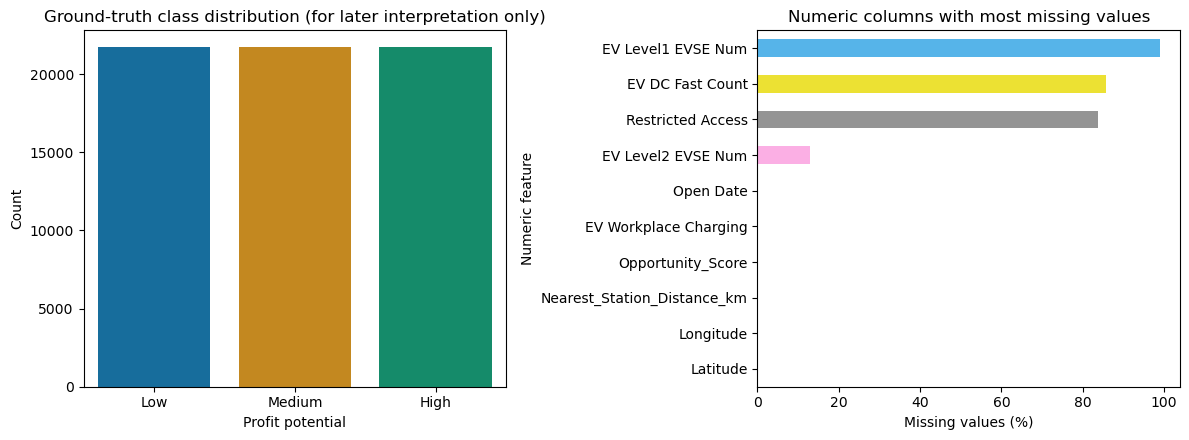

In [2]:
display(df_raw.dtypes.rename('dtype').to_frame())
missing_table = (df_raw.isna().sum().rename('missing_count').to_frame()
                 .assign(missing_pct=lambda x: (100*x['missing_count']/len(df_raw)).round(2))
                 .sort_values('missing_count', ascending=False))
display(missing_table.head(20))
print('Exact duplicate rows:', int(df_raw.duplicated().sum()))
if 'Profit_Potential' in df_raw.columns:
    display(df_raw['Profit_Potential'].value_counts(dropna=False).rename_axis('Profit_Potential').to_frame('count'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
if 'Profit_Potential' in df_raw.columns:
    sns.countplot(data=df_raw, x='Profit_Potential', hue='Profit_Potential', order=['Low','Medium','High'], hue_order=['Low','Medium','High'], ax=axes[0], palette='colorblind', legend=False)
    axes[0].set_title('Ground-truth class distribution (for later interpretation only)')
    axes[0].set_xlabel('Profit potential')
    axes[0].set_ylabel('Count')
else:
    axes[0].axis('off')
num_cols_raw = df_raw.select_dtypes(include=np.number).columns.tolist()
if num_cols_raw:
    missing_pct = (df_raw[num_cols_raw].isna().mean()*100).sort_values(ascending=False).head(10)
    missing_pct.sort_values().plot(kind='barh', ax=axes[1], color=sns.color_palette('colorblind', 10))
    axes[1].set_title('Numeric columns with most missing values')
    axes[1].set_xlabel('Missing values (%)')
    axes[1].set_ylabel('Numeric feature')
plt.tight_layout()
plt.show()

## 3. Prepare unsupervised features without labels or target proxies

- Remove exact duplicate rows.
- Convert `Open Date` to `Open_Year` and create reported charger-capacity/missingness features.
- Exclude `Profit_Potential`, `Competition_Level`, `Opportunity_Score`, and the target-proxy field `Nearest_Station_Distance_km` from the feature matrix.
- Exclude station name, city, and ZIP because their high cardinality can dominate the encoded representation; geographic coordinates and state remain available.
- Select a uniform random subset before fitting; do not stratify by the target.

In [3]:
df = df_raw.drop_duplicates().copy()
if 'Profit_Potential' not in df.columns:
    raise ValueError('Expected ground-truth column Profit_Potential not found; update the notebook for the assigned dataset.')
ground_truth = df['Profit_Potential'].astype('string').str.strip().str.title()

if 'Open Date' in df.columns:
    df['Open_Year'] = pd.to_datetime(df['Open Date'], unit='D', origin='1899-12-30', errors='coerce').dt.year.astype(float)
charger_cols = [c for c in ['EV Level1 EVSE Num','EV Level2 EVSE Num','EV DC Fast Count'] if c in df.columns]
for col in charger_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
if charger_cols:
    df['Total_Reported_EVSE_Count'] = df[charger_cols].fillna(0).sum(axis=1)
    df['Number_of_Charger_Types_Reported'] = df[charger_cols].notna().sum(axis=1)
if 'EV DC Fast Count' in df.columns:
    df['DC_Fast_Count_Reported'] = df['EV DC Fast Count'].notna().astype(int)
    df['Has_Reported_DC_Fast_Charger'] = (df['EV DC Fast Count'].fillna(0) > 0).astype(int)

exclude = [
    'Profit_Potential', 'Competition_Level', 'Opportunity_Score', 'Nearest_Station_Distance_km',
    'Station Name', 'City', 'ZIP', 'Status Code', 'Open Date'
]
X_full = df.drop(columns=exclude, errors='ignore').copy()
constant_cols = [c for c in X_full.columns if X_full[c].nunique(dropna=True) <= 1]
X_full = X_full.drop(columns=constant_cols, errors='ignore')
for col in X_full.select_dtypes(include=['object','string']).columns:
    X_full[col] = X_full[col].astype('object')

y_full = ground_truth.loc[X_full.index] # only retained for post-fit validation

CLUSTER_SAMPLE_SIZE = 2200
sample_size = min(CLUSTER_SAMPLE_SIZE, len(X_full))
X_sample = X_full.sample(n=sample_size, random_state=RANDOM_STATE)
y_sample_after_fit = y_full.loc[X_sample.index]  # not used in fitting, k selection, or sampling

numeric_features = X_sample.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_sample.select_dtypes(exclude=np.number).columns.tolist()
print('Feature matrix before preprocessing:', X_sample.shape)
print('Numeric:', len(numeric_features), '| categorical:', len(categorical_features))
print('Uniform random sample size:', sample_size)
print('Excluded from clustering predictors:', exclude)
print('Constant columns removed:', constant_cols)

def make_cluster_preprocessor():
    numeric_pipe = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    categorical_pipe = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(
            handle_unknown='infrequent_if_exist', min_frequency=20,
            max_categories=20, sparse_output=False
        ))
    ])
    return ColumnTransformer(
        transformers=[
            ('num', numeric_pipe, numeric_features),
            ('cat', categorical_pipe, categorical_features)
        ], remainder='drop', verbose_feature_names_out=False
    )

cluster_preprocessor = make_cluster_preprocessor()
X_cluster = cluster_preprocessor.fit_transform(X_sample)
print('Preprocessed matrix shape:', X_cluster.shape)
print('Any NaN values after preprocessing?', bool(np.isnan(X_cluster).any()))

Feature matrix before preprocessing: (2200, 19)
Numeric: 12 | categorical: 7
Uniform random sample size: 2200
Excluded from clustering predictors: ['Profit_Potential', 'Competition_Level', 'Opportunity_Score', 'Nearest_Station_Distance_km', 'Station Name', 'City', 'ZIP', 'Status Code', 'Open Date']
Constant columns removed: []
Preprocessed matrix shape: (2200, 69)
Any NaN values after preprocessing? False


## 4. K-Means: Elbow curve and candidate cluster counts

Inertia is evaluated from `k=2` through `k=8`. A reproducible elbow heuristic finds the point farthest from the straight line joining the first and last normalized inertia values; use the plotted curve to verify whether this recommendation is sensible for your dataset.

,k,inertia,sampled_silhouette
0,2,"26,646.82",0.4085
1,3,"24,119.71",0.4192
2,4,"22,221.98",0.1610
3,5,"20,019.52",0.1828
4,6,"18,478.84",0.3098
5,7,"16,500.23",0.2254
6,8,"14,508.50",0.2214


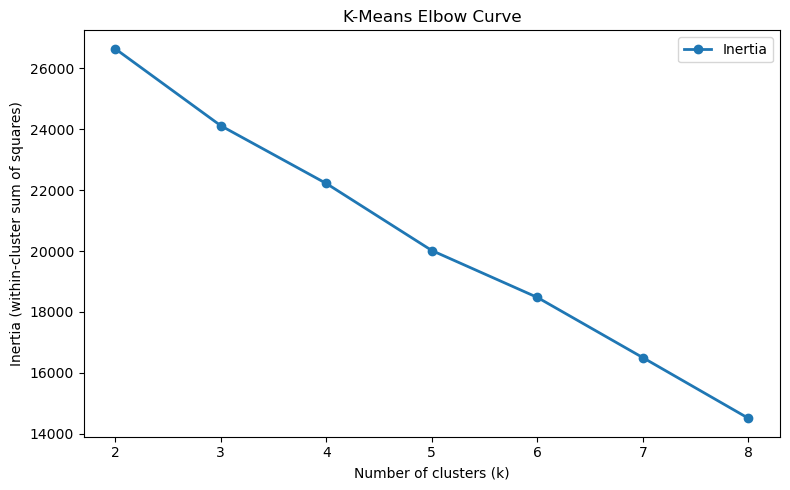

Elbow heuristic recommends k=5. Inspect the plotted curve and record your own justification.


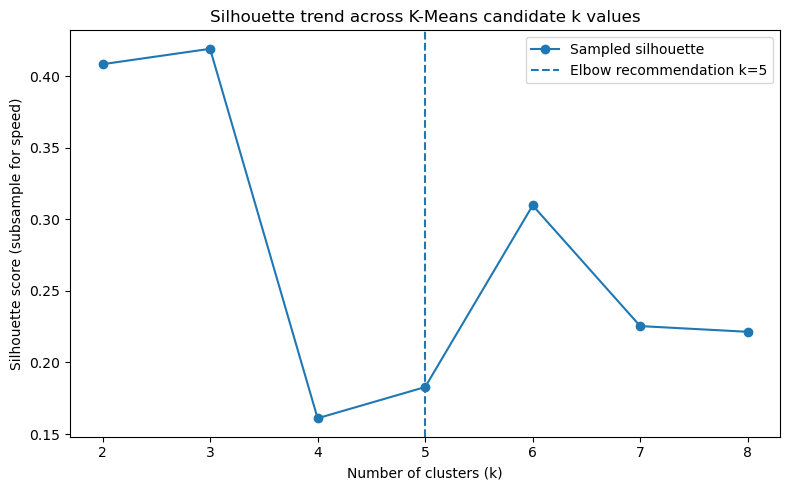

In [4]:
k_values = list(range(2, 9))
elbow_rows = []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_cluster)
    sil_sample = silhouette_score(
        X_cluster, labels,
        sample_size=min(1200, len(X_cluster)),
        random_state=RANDOM_STATE
    )
    elbow_rows.append({'k': k, 'inertia': km.inertia_, 'sampled_silhouette': sil_sample})
elbow_df = pd.DataFrame(elbow_rows)
display(elbow_df.style.format({'inertia':'{:,.2f}', 'sampled_silhouette':'{:.4f}'}))

plt.figure(figsize=(8, 5))
plt.plot(elbow_df['k'], elbow_df['inertia'], marker='o', linewidth=2, label='Inertia')
plt.title('K-Means Elbow Curve')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia (within-cluster sum of squares)')
plt.xticks(k_values)
plt.legend()
plt.tight_layout()
plt.show()

# Elbow heuristic: largest vertical distance below the line between normalized end points.
x_norm = (elbow_df['k'].to_numpy() - min(k_values)) / (max(k_values) - min(k_values))
inertia = elbow_df['inertia'].to_numpy()
y_norm = (inertia - inertia.min()) / (inertia.max() - inertia.min() + 1e-12)
line_y = 1 - x_norm
elbow_distance = line_y - y_norm
K_SELECTED = int(elbow_df.iloc[int(np.argmax(elbow_distance))]['k'])
print(f'Elbow heuristic recommends k={K_SELECTED}. Inspect the plotted curve and record your own justification.')

plt.figure(figsize=(8, 5))
plt.plot(elbow_df['k'], elbow_df['sampled_silhouette'], marker='o', label='Sampled silhouette')
plt.axvline(K_SELECTED, linestyle='--', label=f'Elbow recommendation k={K_SELECTED}')
plt.title('Silhouette trend across K-Means candidate k values')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score (subsample for speed)')
plt.xticks(k_values)
plt.legend()
plt.tight_layout()
plt.show()

## 5. Fit K-Means and Agglomerative clustering

K-Means is fitted using the recommended `k`. Agglomerative clustering is fitted using Ward, complete, and average linkage so that linkage strategies can be compared. The ground-truth target is not passed to any clustering estimator.

In [5]:
cluster_labels = {}
cluster_models = {}

kmeans_model = KMeans(n_clusters=K_SELECTED, n_init=20, random_state=RANDOM_STATE)
cluster_labels['K-Means'] = kmeans_model.fit_predict(X_cluster)
cluster_models['K-Means'] = kmeans_model

for linkage_name in ['ward', 'complete', 'average']:
    start = time.time()
    if linkage_name == 'ward':
        estimator = AgglomerativeClustering(n_clusters=K_SELECTED, linkage=linkage_name)
    else:
        estimator = AgglomerativeClustering(n_clusters=K_SELECTED, linkage=linkage_name, metric='euclidean')
    labels = estimator.fit_predict(X_cluster)
    display_name = f'Agglomerative ({linkage_name})'
    cluster_labels[display_name] = labels
    cluster_models[display_name] = estimator
    print(f'{display_name} fitted in {time.time() - start:.1f}s')

cluster_sizes = []
for name, labels in cluster_labels.items():
    counts = pd.Series(labels).value_counts().sort_index()
    cluster_sizes.append({'Algorithm': name, 'Clusters found': len(np.unique(labels)), 'Smallest cluster': int(counts.min()), 'Largest cluster': int(counts.max())})
display(pd.DataFrame(cluster_sizes))

Agglomerative (ward) fitted in 0.3s
Agglomerative (complete) fitted in 0.3s
Agglomerative (average) fitted in 0.3s


,Algorithm,Clusters found,Smallest cluster,Largest cluster
0,K-Means,5,28,982
1,Agglomerative (ward),5,42,1737
2,Agglomerative (complete),5,1,2111
3,Agglomerative (average),5,1,2187


## 6. Required clustering evaluation metrics

All three internal metrics are calculated for each fitted algorithm: Silhouette (higher is better), Davies-Bouldin (lower is better), and Calinski-Harabasz (higher is generally better). ARI and NMI are optional external validation metrics calculated only after cluster fitting, using `Profit_Potential` as ground truth; they were not used to choose clusters or train models.

In [8]:
metric_rows = []
for name, labels in cluster_labels.items():
    row = {
        'Algorithm / linkage': name,
        'Clusters': len(np.unique(labels)),
        'Silhouette Score': silhouette_score(X_cluster, labels),
        'Davies-Bouldin Index': davies_bouldin_score(X_cluster, labels),
        'Calinski-Harabasz Index': calinski_harabasz_score(X_cluster, labels),
    }
    # External label comparison only after clustering has been completed.
    valid = y_sample_after_fit.notna()
    if valid.sum() == len(labels) and y_sample_after_fit.nunique() > 1:
        row['ARI vs Profit_Potential (post-fit)'] = adjusted_rand_score(y_sample_after_fit.to_numpy(), labels)
        row['NMI vs Profit_Potential (post-fit)'] = normalized_mutual_info_score(y_sample_after_fit.to_numpy(), labels)
    metric_rows.append(row)

cluster_metrics_df = pd.DataFrame(metric_rows).sort_values('Silhouette Score', ascending=False).reset_index(drop=True)
display(cluster_metrics_df.style.format({c:'{:.4f}' for c in cluster_metrics_df.columns if c not in ['Algorithm / linkage','Clusters']}))

out_candidates = [Path('../outputs'), Path('outputs')]
OUTPUT_DIR = next((p for p in out_candidates if p.exists()), Path.cwd())
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
cluster_metrics_df.to_csv(OUTPUT_DIR / 'clustering_metrics_comparison.csv', index=False)
elbow_df.to_csv(OUTPUT_DIR / 'kmeans_elbow_and_silhouette.csv', index=False)
print('Saved metrics and elbow table in:', OUTPUT_DIR.resolve())

,Algorithm / linkage,Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,ARI vs Profit_Potential (post-fit),NMI vs Profit_Potential (post-fit)
0,Agglomerative (average),5,0.6672,0.3758,96.9217,-0.0000,0.0049
1,Agglomerative (complete),5,0.4832,0.7358,147.4097,0.0020,0.0217
2,Agglomerative (ward),5,0.4274,1.4240,329.2428,0.0097,0.0231
3,K-Means,5,0.1856,1.5960,331.9851,0.0125,0.0204


Saved metrics and elbow table in: C:\Users\vedha\EVGuard\notebooks


## 7. Dendrogram for hierarchical clustering

A full dendrogram for all 2,200 sampled observations would be difficult to read, so the displayed dendrogram is computed on a reproducible subset of at most 700 observations and truncated to its last merges. The hierarchical cluster models and metric table above are still fitted/evaluated on the full clustering sample.

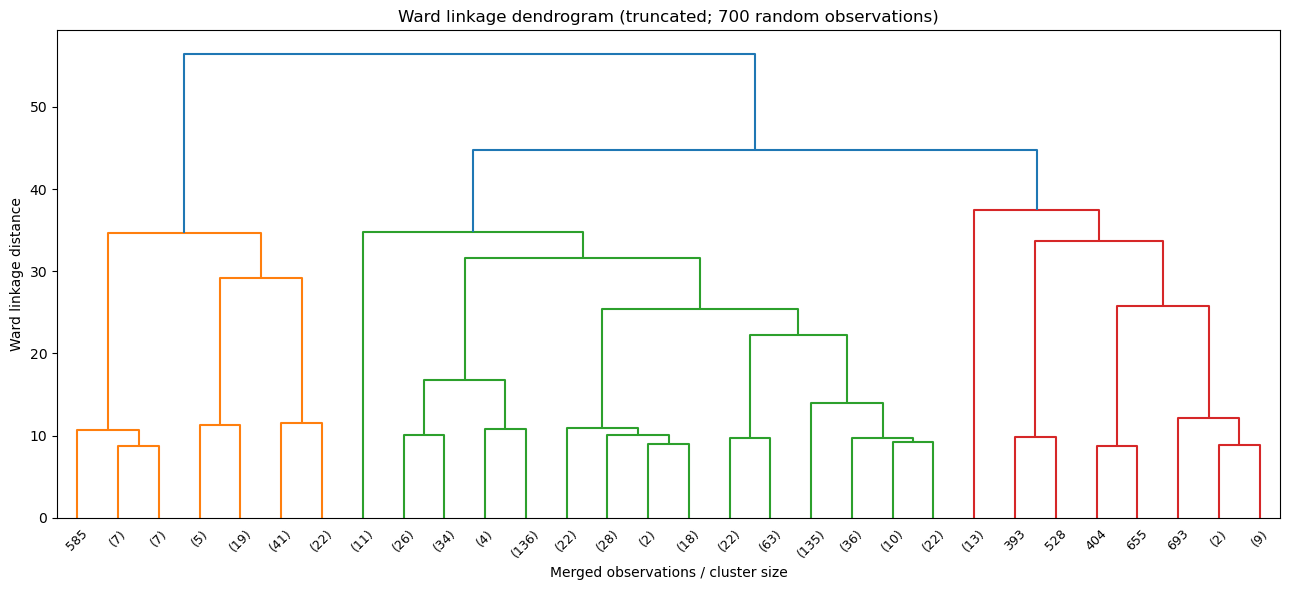

In [9]:
DENDROGRAM_SAMPLE_SIZE = min(700, len(X_cluster))
rng = np.random.default_rng(RANDOM_STATE)
dendro_indices = np.sort(rng.choice(len(X_cluster), size=DENDROGRAM_SAMPLE_SIZE, replace=False))
X_dendro = X_cluster[dendro_indices]
Z = linkage(X_dendro, method='ward', metric='euclidean')
plt.figure(figsize=(13, 6))
dendrogram(Z, truncate_mode='lastp', p=30, show_leaf_counts=True, leaf_rotation=45, leaf_font_size=9)
plt.title(f'Ward linkage dendrogram (truncated; {DENDROGRAM_SAMPLE_SIZE} random observations)')
plt.xlabel('Merged observations / cluster size')
plt.ylabel('Ward linkage distance')
plt.tight_layout()
plt.show()

## 8. Mandatory PCA 2D visualization for every fitted algorithm

PCA is used only to project the already-preprocessed features to two dimensions for visualization. Clusters are not trained in the PCA plane; each plot colors the same 2D projection using the labels from the respective fitted algorithm.

PCA explained variance ratio: [0.1884 0.1308]
Total variance represented by PC1 + PC2: 0.3192


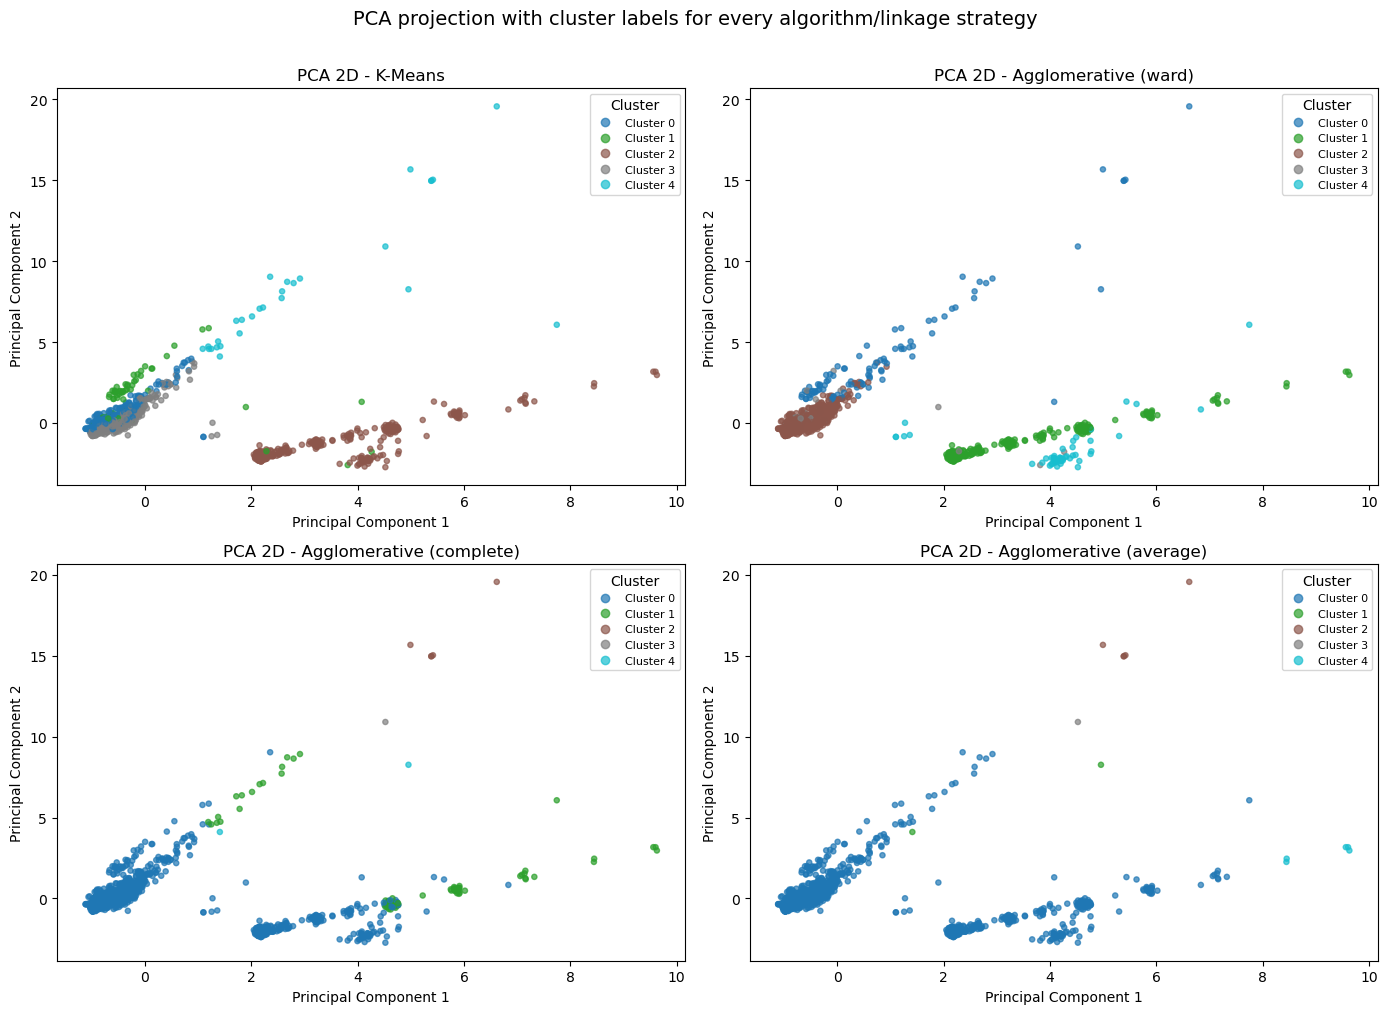

In [10]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_cluster)
print('PCA explained variance ratio:', np.round(pca.explained_variance_ratio_, 4))
print('Total variance represented by PC1 + PC2:', round(float(pca.explained_variance_ratio_.sum()), 4))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (name, labels) in zip(axes.flat, cluster_labels.items()):
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='tab10', s=14, alpha=0.7)
    ax.set_title(f'PCA 2D - {name}')
    ax.set_xlabel('Principal Component 1')
    ax.set_ylabel('Principal Component 2')
    handles, legend_labels = scatter.legend_elements()
    ax.legend(handles, [f'Cluster {lab}' for lab in np.unique(labels)], title='Cluster', loc='best', fontsize=8)
plt.suptitle('PCA projection with cluster labels for every algorithm/linkage strategy', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

## 9. Encouraged t-SNE visualization

t-SNE is computed on a reproducible subset of the clustering feature matrix for runtime reasons and is colored by the already-fitted K-Means labels. This is a visualization only; it does not change the fitted clusters or their scores.

t-SNE completed for 1000 points in 4.8s; perplexity=30.0


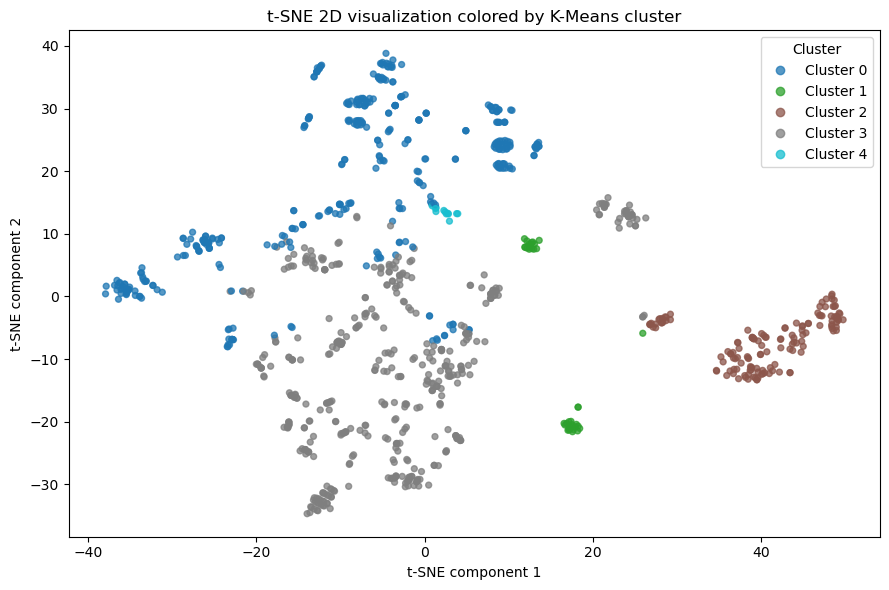

In [12]:
TSNE_SAMPLE_SIZE = min(1000, len(X_cluster))
tsne_indices = np.sort(rng.choice(len(X_cluster), size=TSNE_SAMPLE_SIZE, replace=False))
X_tsne_input = X_cluster[tsne_indices]
kmeans_labels_tsne = cluster_labels['K-Means'][tsne_indices]
perplexity = min(30.0, max(5.0, (TSNE_SAMPLE_SIZE - 1) / 3.0))
tsne_model = TSNE(
    n_components=2, perplexity=perplexity, init='pca', learning_rate='auto',
    max_iter=750, random_state=RANDOM_STATE
)
start = time.time()
X_tsne = tsne_model.fit_transform(X_tsne_input)
print(f't-SNE completed for {TSNE_SAMPLE_SIZE} points in {time.time() - start:.1f}s; perplexity={perplexity:.1f}')
plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=kmeans_labels_tsne, cmap='tab10', s=18, alpha=0.75)
plt.title('t-SNE 2D visualization colored by K-Means cluster')
plt.xlabel('t-SNE component 1')
plt.ylabel('t-SNE component 2')
handles, labs = scatter.legend_elements()
plt.legend(handles, [f'Cluster {lab}' for lab in np.unique(kmeans_labels_tsne)], title='Cluster')
plt.tight_layout()
plt.show()